# Deadlift Prediction — Initial Data Exploration

## Goal
Prepare the OpenPowerlifting data for a linear regression model that predicts a person's **maximum deadlift in kilograms**. This first step loads the raw CSV into a pandas DataFrame so we can inspect its structure before deciding how to clean and transform it.


In [45]:
from pathlib import Path

import pandas as pd

# Resolve the raw dataset path from this notebook's location (src/).
project_root = Path.cwd()
if project_root.name == "src":
    project_root = project_root.parent

raw_csv_path = project_root / "data" / "raw" / "openpowerlifting-2021-06-26-027dc895.csv"

# Load the raw source without modifying it.
df = pd.read_csv(raw_csv_path, low_memory=False)

print(f"Loaded {len(df):,} rows and {len(df.columns):,} columns from:")
print(">>> these are the columns:", df.columns)
print(raw_csv_path)
df.head()


Loaded 2,490,480 rows and 41 columns from:
>>> these are the columns: Index(['Name', 'Sex', 'Event', 'Equipment', 'Age', 'AgeClass',
       'BirthYearClass', 'Division', 'BodyweightKg', 'WeightClassKg',
       'Squat1Kg', 'Squat2Kg', 'Squat3Kg', 'Squat4Kg', 'Best3SquatKg',
       'Bench1Kg', 'Bench2Kg', 'Bench3Kg', 'Bench4Kg', 'Best3BenchKg',
       'Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg', 'Deadlift4Kg',
       'Best3DeadliftKg', 'TotalKg', 'Place', 'Dots', 'Wilks', 'Glossbrenner',
       'Goodlift', 'Tested', 'Country', 'State', 'Federation',
       'ParentFederation', 'Date', 'MeetCountry', 'MeetState', 'MeetTown',
       'MeetName'],
      dtype='str')
/home/ernesto/4GeeksAcademy/mia-ai-3/machine-learning-deadlift-predictor/data/raw/openpowerlifting-2021-06-26-027dc895.csv


,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Tested,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName
0,Dominik Gabriel,M,B,Raw,17.0,16-17,14-18,T 16-17,102.5,110,...,NaN,Slovakia,NaN,WUAP,WUAP,2015-06-16,Czechia,NaN,Praha,European Championships
1,Marek Herák,M,B,Multi-ply,19.0,18-19,19-23,T 18-19,59.8,60,...,NaN,Slovakia,NaN,WUAP,WUAP,2015-06-16,Czechia,NaN,Praha,European Championships
2,Miroslav Adamove,M,B,Multi-ply,18.0,18-19,14-18,T 18-19,87.7,90,...,NaN,Slovakia,NaN,WUAP,WUAP,2015-06-16,Czechia,NaN,Praha,European Championships
3,Kamil Lipiňski,M,B,Multi-ply,19.0,18-19,19-23,T 18-19,89.5,90,...,NaN,Poland,NaN,WUAP,WUAP,2015-06-16,Czechia,NaN,Praha,European Championships
4,Gabriel Kováč,M,B,Multi-ply,20.0,20-23,19-23,Juniors,81.6,82.5,...,NaN,Slovakia,NaN,WUAP,WUAP,2015-06-16,Czechia,NaN,Praha,European Championships


## Create the deadlift target

Failed attempts are represented by negative values, and zeros or missing values do not count as successful lifts. We will use the maximum positive value across the individual deadlift attempts and the meet-level `Best3DeadliftKg` field as `max_deadlift_kg`. Rows without any positive successful deadlift are removed. After creating the target, the individual `DeadliftNKg` attempt columns are dropped.


In [46]:
import re

attempt_columns = [
    column for column in df.columns
    if re.fullmatch(r"Deadlift\d+Kg", column)
]

# The benchmark's Best3DeadliftKg field is also used as the target source.
if "Best3DeadliftKg" in df.columns:
    target_source_columns = attempt_columns + ["Best3DeadliftKg"]
else:
    target_source_columns = attempt_columns

if not target_source_columns:
    raise ValueError("No deadlift attempt or best-lift columns were found.")

# Coerce unexpected non-numeric entries to NaN, then ignore failed (<= 0) attempts.
deadlift_attempts = df[target_source_columns].apply(pd.to_numeric, errors="coerce")
deadlift_attempts = deadlift_attempts.where(deadlift_attempts > 0)

df["max_deadlift_kg"] = deadlift_attempts.max(axis=1)

rows_before_filter = len(df)
df = df.loc[df["max_deadlift_kg"].notna() & (df["max_deadlift_kg"] > 0)].copy()
print(f"Dropped {rows_before_filter - len(df):,} rows without a successful deadlift.")

# Remove individual attempt columns after the target has been created.
df = df.drop(columns=target_source_columns)

print(f"Remaining rows: {len(df):,}")
print(f"Attempt columns removed: {target_source_columns}")
df[["max_deadlift_kg"]].head()


Dropped 722,210 rows without a successful deadlift.
Remaining rows: 1,768,270
Attempt columns removed: ['Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg', 'Deadlift4Kg', 'Best3DeadliftKg']


,max_deadlift_kg
180,200.0
181,170.0
182,265.5
183,172.5
184,200.0


## Create squat and bench features

Create `max_squat_kg` and `max_bench_kg` from the maximum positive value in each lift's numbered attempt columns and corresponding `Best3...Kg` summary column. Failed (negative), zero, and missing values are ignored. These are auxiliary features, so rows with no successful squat or bench remain in the dataset with a missing feature value. Drop the raw attempt and `Best3SquatKg` / `Best3BenchKg` columns after creating the new columns.


In [47]:
lift_cleanup_columns = []

for lift_name, best_column, target_column in [
    ("Squat", "Best3SquatKg", "max_squat_kg"),
    ("Bench", "Best3BenchKg", "max_bench_kg"),
]:
    attempt_columns = [
        column for column in df.columns
        if re.fullmatch(rf"{lift_name}\d+Kg", column)
    ]
    source_columns = attempt_columns.copy()
    if best_column in df.columns:
        source_columns.append(best_column)

    if source_columns:
        successful_lifts = df[source_columns].apply(pd.to_numeric, errors="coerce")
        successful_lifts = successful_lifts.where(successful_lifts > 0)
        df[target_column] = successful_lifts.max(axis=1)
        lift_cleanup_columns.extend(source_columns)
    else:
        df[target_column] = pd.NA
        print(f"Warning: no {lift_name.lower()} source columns found; {target_column} is missing.")

# Drop the source attempt and Best3 columns, keeping the new feature columns.
lift_cleanup_columns = list(dict.fromkeys(lift_cleanup_columns))
df = df.drop(columns=lift_cleanup_columns)

print(f"Squat/bench source columns removed: {lift_cleanup_columns}")
df[["max_squat_kg", "max_bench_kg", "max_deadlift_kg"]].head()
print(f">>> current records in dataset: {df.count()}")

Squat/bench source columns removed: ['Squat1Kg', 'Squat2Kg', 'Squat3Kg', 'Squat4Kg', 'Best3SquatKg', 'Bench1Kg', 'Bench2Kg', 'Bench3Kg', 'Bench4Kg', 'Best3BenchKg']
>>> current records in dataset: Name                1768270
Sex                 1768270
Event               1768270
Equipment           1768270
Age                 1007450
AgeClass            1196697
BirthYearClass      1046945
Division            1766525
BodyweightKg        1754154
WeightClassKg       1758266
TotalKg             1746176
Place               1768270
Dots                1732196
Wilks               1732196
Glossbrenner        1732196
Goodlift            1546046
Tested              1344532
Country              912902
State                350900
Federation          1768270
ParentFederation    1088885
Date                1768270
MeetCountry         1768270
MeetState           1366334
MeetTown            1538224
MeetName            1768270
max_deadlift_kg     1768270
max_squat_kg        1571597
max_bench_kg       

## Remove non-feature and leakage-prone columns

Keep `Name` temporarily for a lifter-grouped train/test split, but remove it from model features and exported files. Drop derived competition outcomes, scoring metrics, age-class fields, location/meet identifiers, and the other fields excluded from this baseline. Keep the raw `df` limited to the remaining candidate features, `Name`, and the target.


In [48]:
columns_to_drop = [
    "BirthYearClass",
    "AgeClass",
    "TotalKg",
    "Place",
    "Dots",
    "Wilks",
    "Glossbrenner",
    "Goodlift",
    "Country",
    "State",
    "Federation",
    "ParentFederation",
    "Tested",
    "Division",
    "WeightClassKg",
    "Date",
    "MeetCountry",
    "MeetState",
    "MeetTown",
    "MeetName",
]

# Drop only columns present in this dataset; retain Name for group splitting.
columns_dropped = [column for column in columns_to_drop if column in df.columns]
df = df.drop(columns=columns_dropped)

print(f"Dropped columns: {columns_dropped}")
print(f"Name retained for splitting: {'Name' in df.columns}")
print(f"DataFrame shape after cleanup: {df.shape}")


Dropped columns: ['BirthYearClass', 'AgeClass', 'TotalKg', 'Place', 'Dots', 'Wilks', 'Glossbrenner', 'Goodlift', 'Country', 'State', 'Federation', 'ParentFederation', 'Tested', 'Division', 'WeightClassKg', 'Date', 'MeetCountry', 'MeetState', 'MeetTown', 'MeetName']
Name retained for splitting: True
DataFrame shape after cleanup: (1768270, 9)


## Select model features and create group-aware train/validation/test splits

For this prediction scenario, assume squat and bench maxima are already available, so include `max_squat_kg` and `max_bench_kg` as features. `Name` is used only to keep each lifter in one split; it is not a model feature and will not be exported. First reserve 20% of lifter groups for the final test set, then reserve 20% of the remaining groups for validation. Group-based percentages are approximate because lifters can have different numbers of competition records.


In [49]:
from sklearn.model_selection import GroupShuffleSplit

# Explicitly allowlist features so identifiers and target-derived columns cannot leak in.
feature_columns = [
    "Sex",
    "Equipment",
    "Age",
    "BodyweightKg",
    "Event",
    "max_squat_kg",
    "max_bench_kg",
]
target_column = "max_deadlift_kg"
group_column = "Name"

required_columns = feature_columns + [target_column, group_column]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise KeyError(f"Required columns are missing: {missing_columns}")

# Rows without a name cannot be assigned to a lifter group reliably.
rows_before_named = len(df)
df = df.dropna(subset=[group_column]).copy()
print(f"Dropped {rows_before_named - len(df):,} rows with no Name for group splitting.")

X = df[feature_columns].copy()
y = df[target_column].copy()
groups = df[group_column]

# First reserve 20% of lifter groups for the final test set.
test_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_validation_indices, test_indices = next(test_splitter.split(X, y, groups=groups))

X_train_validation = X.iloc[train_validation_indices].copy()
y_train_validation = y.iloc[train_validation_indices].copy()
groups_train_validation = groups.iloc[train_validation_indices]

X_test = X.iloc[test_indices].copy()
y_test = y.iloc[test_indices].copy()
test_names = groups.iloc[test_indices]

# Split the remaining lifters into training and validation groups.
# 20% of the remaining 80% is approximately 16% of the full dataset.
validation_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=43)
train_indices, validation_indices = next(
    validation_splitter.split(
        X_train_validation,
        y_train_validation,
        groups=groups_train_validation,
    )
)

X_train = X_train_validation.iloc[train_indices].copy()
y_train = y_train_validation.iloc[train_indices].copy()
train_names = groups_train_validation.iloc[train_indices]

X_validation = X_train_validation.iloc[validation_indices].copy()
y_validation = y_train_validation.iloc[validation_indices].copy()
validation_names = groups_train_validation.iloc[validation_indices]

# Verify all three splits are isolated by lifter name.
assert set(train_names).isdisjoint(set(validation_names)), "A lifter appears in train and validation."
assert set(train_names).isdisjoint(set(test_names)), "A lifter appears in train and test."
assert set(validation_names).isdisjoint(set(test_names)), "A lifter appears in validation and test."

print(f"Train rows: {len(X_train):,}; groups: {train_names.nunique():,}")
print(f"Validation rows: {len(X_validation):,}; groups: {validation_names.nunique():,}")
print(f"Test rows: {len(X_test):,}; groups: {test_names.nunique():,}")
print(f"Features: {feature_columns}")


Dropped 0 rows with no Name for group splitting.
Train rows: 1,128,573; groups: 336,158
Validation rows: 283,778; groups: 84,040
Test rows: 355,919; groups: 105,050
Features: ['Sex', 'Equipment', 'Age', 'BodyweightKg', 'Event', 'max_squat_kg', 'max_bench_kg']


## Preprocess features using the training split

Fit imputation, scaling, and category encoding using `X_train` only. Apply those same fitted transformations to the validation and test features so neither split influences preprocessing. Numeric features use median imputation followed by standard scaling. Categorical features use most-frequent imputation followed by one-hot encoding; categories absent from training are safely ignored. Keep `max_deadlift_kg` (`y`) in kilograms and do not scale it.


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["Sex", "Equipment", "Event"]
numeric_features = [
    "Age",
    "BodyweightKg",
    "max_squat_kg",
    "max_bench_kg",
]

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

# Fit on training data only; transform validation and test with the same fitted object.
X_train_processed_array = preprocessor.fit_transform(X_train)
X_validation_processed_array = preprocessor.transform(X_validation)
X_test_processed_array = preprocessor.transform(X_test)
processed_feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed_array,
    columns=processed_feature_names,
    index=X_train.index,
)
X_validation_processed = pd.DataFrame(
    X_validation_processed_array,
    columns=processed_feature_names,
    index=X_validation.index,
)
X_test_processed = pd.DataFrame(
    X_test_processed_array,
    columns=processed_feature_names,
    index=X_test.index,
)

print(f"Processed train shape: {X_train_processed.shape}")
print(f"Processed validation shape: {X_validation_processed.shape}")
print(f"Processed test shape: {X_test_processed.shape}")
print(f"Missing processed train values: {int(X_train_processed.isna().sum().sum())}")
print(f"Missing processed validation values: {int(X_validation_processed.isna().sum().sum())}")
print(f"Missing processed test values: {int(X_test_processed.isna().sum().sum())}")


Processed train shape: (1128573, 17)
Processed validation shape: (283778, 17)
Processed test shape: (355919, 17)
Missing processed train values: 0
Missing processed validation values: 0
Missing processed test values: 0


In [32]:
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

X_train_processed.to_csv(processed_dir / "X_train.csv", index=False)
y_train.to_frame(name=target_column).to_csv(processed_dir / "y_train.csv", index=False)

X_validation_processed.to_csv(processed_dir / "X_validation.csv", index=False)
y_validation.to_frame(name=target_column).to_csv(
    processed_dir / "y_validation.csv", index=False
)

X_test_processed.to_csv(processed_dir / "X_test.csv", index=False)
y_test.to_frame(name=target_column).to_csv(processed_dir / "y_test.csv", index=False)

print(f"Saved train, validation, and test files to: {processed_dir}")


Saved train, validation, and test files to: /home/ernesto/4GeeksAcademy/mia-ai-3/machine-learning-deadlift-predictor/data/processed


# Segment 2: Train and evaluate regression models

Use the saved train, validation, and test files to compare ready-to-use scikit-learn regressors. The validation set guides model selection; keep the test set for one final evaluation after choosing a model.


## 1. Load and check the prepared data

Load the six CSV files created in Segment 1. Confirm that each feature split has the same columns as the training set and that each target has the expected number of rows. The feature files contain imputed, scaled, and one-hot encoded values; the target remains in kilograms.


In [51]:
import pandas as pd

processed_dir = project_root / "data" / "processed"

X_train_model = pd.read_csv(processed_dir / "X_train.csv")
y_train_model = pd.read_csv(processed_dir / "y_train.csv")[target_column]

X_validation_model = pd.read_csv(processed_dir / "X_validation.csv")
y_validation_model = pd.read_csv(processed_dir / "y_validation.csv")[target_column]

X_test_model = pd.read_csv(processed_dir / "X_test.csv")
y_test_model = pd.read_csv(processed_dir / "y_test.csv")[target_column]

assert X_train_model.columns.equals(X_validation_model.columns)
assert X_train_model.columns.equals(X_test_model.columns)
assert len(X_train_model) == len(y_train_model)
assert len(X_validation_model) == len(y_validation_model)
assert len(X_test_model) == len(y_test_model)

print(f"Train:      X={X_train_model.shape}, y={y_train_model.shape}")
print(f"Validation: X={X_validation_model.shape}, y={y_validation_model.shape}")
print(f"Test:       X={X_test_model.shape}, y={y_test_model.shape}")


Train:      X=(1128573, 17), y=(1128573,)
Validation: X=(283778, 17), y=(283778,)
Test:       X=(355919, 17), y=(355919,)


## 2. Create a baseline prediction

A `DummyRegressor` is a simple reference model. With the `mean` strategy, it predicts the average deadlift in the training set for every row. A useful model should improve on this baseline on validation data.


In [52]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train_model, y_train_model)
validation_predictions_baseline = baseline_model.predict(X_validation_model)

print("Baseline prediction (mean deadlift, kg):", round(baseline_model.constant_[0][0], 2))


Baseline prediction (mean deadlift, kg): 188.8


## 3. Train the first regression model

`LinearRegression` is a ready-to-use scikit-learn model that learns a linear relationship between the features and deadlift. Fit it using the training split, then predict the validation split. Do not fit on validation or test data.


In [53]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_model, y_train_model)
validation_predictions_linear = linear_model.predict(X_validation_model)

print("Generated validation predictions:", len(validation_predictions_linear))


Generated validation predictions: 283778


## 4. Evaluate with regression metrics

Use MAE and RMSE to describe prediction error in kilograms. Lower values are better. R² describes how much target variation is explained by the model; closer to 1 is generally better, while it can be negative when a model performs worse than predicting the mean. Compare both models on the same validation data.


In [54]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_metrics(actual, predicted):
    return {
        "MAE (kg)": mean_absolute_error(actual, predicted),
        "RMSE (kg)": mean_squared_error(actual, predicted) ** 0.5,
        "R²": r2_score(actual, predicted),
    }


validation_results = pd.DataFrame.from_dict(
    {
        "Dummy mean baseline": regression_metrics(
            y_validation_model, validation_predictions_baseline
        ),
        "Linear regression": regression_metrics(
            y_validation_model, validation_predictions_linear
        ),
    },
    orient="index",
)

validation_results.round(3)


,MAE (kg),RMSE (kg),R²
Dummy mean baseline,51.276,61.626,-0.0
Linear regression,19.569,27.526,0.8


## 5. Compare with Ridge regression (optional)

Ridge is another built-in linear model. It adds regularization, which can help when features are correlated. We use a common default `alpha=1.0` for a simple first comparison; tuning it can be a later exercise. Compare Ridge on the same validation set and metrics.


In [55]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_model, y_train_model)
validation_predictions_ridge = ridge_model.predict(X_validation_model)

validation_results.loc["Ridge regression (alpha=1.0)"] = regression_metrics(
    y_validation_model, validation_predictions_ridge
)
validation_results.round(3)


,MAE (kg),RMSE (kg),R²
Dummy mean baseline,51.276,61.626,-0.0
Linear regression,19.569,27.526,0.8
Ridge regression (alpha=1.0),19.569,27.526,0.8


## 6. Select a model using validation results

Choose between Linear Regression and Ridge using validation MAE (lower is better). The dummy model is only a baseline, not a candidate for the final model. A small actual-versus-predicted plot can help us see how close predictions are to the ideal diagonal; this is a diagnostic, not a replacement for the metrics.


Selected using validation MAE: Linear regression


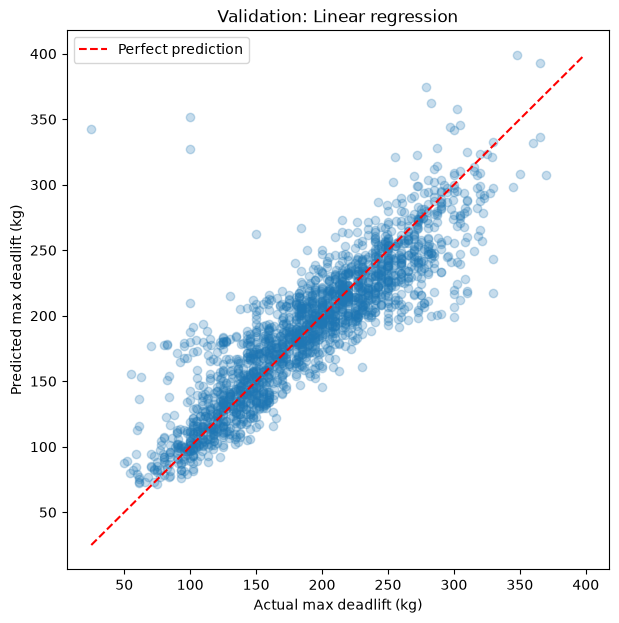

In [56]:
import matplotlib.pyplot as plt

candidate_models = {
    "Linear regression": (linear_model, validation_predictions_linear),
    "Ridge regression (alpha=1.0)": (ridge_model, validation_predictions_ridge),
}
selected_model_name = min(
    candidate_models,
    key=lambda name: validation_results.loc[name, "MAE (kg)"],
)
selected_model = candidate_models[selected_model_name][0]
selected_validation_predictions = candidate_models[selected_model_name][1]

print(f"Selected using validation MAE: {selected_model_name}")

# Plot a small, deterministic sample to keep the chart readable.
plot_sample = pd.DataFrame(
    {
        "actual": y_validation_model,
        "predicted": selected_validation_predictions,
    }
).sample(n=min(2000, len(y_validation_model)), random_state=42)

axis_limits = [
    min(plot_sample["actual"].min(), plot_sample["predicted"].min()),
    max(plot_sample["actual"].max(), plot_sample["predicted"].max()),
]

plt.figure(figsize=(7, 7))
plt.scatter(plot_sample["actual"], plot_sample["predicted"], alpha=0.25)
plt.plot(axis_limits, axis_limits, color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual max deadlift (kg)")
plt.ylabel("Predicted max deadlift (kg)")
plt.title(f"Validation: {selected_model_name}")
plt.legend()
plt.show()


## 7. Refit the selected model and evaluate on the test set

After selecting a model with validation MAE, combine the transformed training and validation rows and refit that model. The test set has not been used for training or model selection, so use it once for the final estimate. These CSV features share the transformation fitted on the original training split; this step refits the regressor, not the imputer, scaler, or encoder.


In [57]:
from sklearn.base import clone

X_train_validation_model = pd.concat(
    [X_train_model, X_validation_model],
    ignore_index=True,
)
y_train_validation_model = pd.concat(
    [y_train_model, y_validation_model],
    ignore_index=True,
)

final_model = clone(selected_model)
final_model.fit(X_train_validation_model, y_train_validation_model)
test_predictions = final_model.predict(X_test_model)

test_results = pd.DataFrame.from_dict(
    {selected_model_name: regression_metrics(y_test_model, test_predictions)},
    orient="index",
)
test_results.round(3)


,MAE (kg),RMSE (kg),R²
Linear regression,19.762,27.896,0.796


## 8. Use the trained model for new lifters

The prediction input must use the same feature names and original feature types as the training data. Apply the already-fitted preprocessor, then pass the transformed row to the final selected model. The first example deliberately leaves some fields missing to demonstrate training-fitted imputation; its prediction is illustrative and uses typical training-set values for those fields. The second example supplies bodyweight, equipment, and event.


In [58]:
# The feature names and column order must match the data used to fit the preprocessor.
inference_feature_columns = [
    "Sex",
    "Equipment",
    "Age",
    "BodyweightKg",
    "Event",
    "max_squat_kg",
    "max_bench_kg",
]

# Use np.nan so scikit-learn's numeric imputer can recognize missing values.
missing_value = float("nan")

# Example 1: partial information. Missing context is imputed using training-set values.
lifter_partial = pd.DataFrame(
    [
        {
            "Sex": "M",
            "Equipment": missing_value,
            "Age": 42,
            "BodyweightKg": missing_value,
            "Event": missing_value,
            "max_squat_kg": 118,
            "max_bench_kg": 102,
        }
    ],
    columns=inference_feature_columns,
)

# Example 2: same lifter with bodyweight and competition context supplied.
lifter_with_context = pd.DataFrame(
    [
        {
            "Sex": "M",
            "Equipment": "Raw",
            "Age": 42,
            "BodyweightKg": 81,
            "Event": "SBD",
            "max_squat_kg": 118,
            "max_bench_kg": 102,
        }
    ],
    columns=inference_feature_columns,
)

# Reuse fitted preprocessing and the final model; do not refit either here.
# Wrap transformed arrays as DataFrames to preserve the trained feature names.
partial_features_processed = pd.DataFrame(
    preprocessor.transform(lifter_partial),
    columns=X_train_model.columns,
)
context_features_processed = pd.DataFrame(
    preprocessor.transform(lifter_with_context),
    columns=X_train_model.columns,
)

partial_deadlift_prediction = final_model.predict(partial_features_processed)[0]
context_deadlift_prediction = final_model.predict(context_features_processed)[0]

inference_results = pd.DataFrame(
    {
        "Scenario": ["Missing context (imputed)", "Bodyweight + Raw + SBD supplied"],
        "Predicted max deadlift (kg)": [
            partial_deadlift_prediction,
            context_deadlift_prediction,
        ],
    }
)
inference_results["Predicted max deadlift (kg)"] = inference_results[
    "Predicted max deadlift (kg)"
].round(1)
inference_results


,Scenario,Predicted max deadlift (kg)
0,Missing context (imputed),159.6
1,Bodyweight + Raw + SBD supplied,173.5
